# 03bis V4 — Forêt OSM robuste aux grands polygones englobants

Cette version corrige le cas où la trace GPX est située à l'intérieur d'un grand massif forestier dont la frontière est loin de la petite bbox.

Stratégies combinées :

```text
A. petite bbox autour de la route
B. is_in sur des points de contrôle le long du GPX + pivot
C. bbox élargie de secours si la couverture reste très faible
```

La sortie reste compatible avec le notebook 04 :

```text
data/output/terrain_forest_annotations.json
```

**Correctif :** les séparateurs de lignes QL sont maintenant de véritables retours à la ligne ; une validation locale est effectuée avant les appels Overpass. Les erreurs HTTP permanentes incluent le serveur et la requête concernés.

In [16]:
import hashlib, json, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from pyproj import Transformer
from shapely.geometry import LineString, Polygon, Point
from shapely.ops import transform, unary_union, polygonize

## 1. Charger la route

In [17]:
route_path = Path("data/output/route_resampled.csv")
if not route_path.exists():
    raise FileNotFoundError("Exécute d'abord le notebook 02.")

route = pd.read_csv(route_path)
required = {"distance_m","lat","lon","elev_m"}
missing = required - set(route.columns)
if missing:
    raise ValueError(f"Colonnes manquantes : {sorted(missing)}")

print("Points :", len(route))
print("Longueur :", round(route["distance_m"].iloc[-1],1), "m")

Points : 899
Longueur : 8978.8 m


## 2. Configuration

In [18]:
OVERPASS_ENDPOINTS = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.private.coffee/api/interpreter",
    "https://maps.mail.ru/osm/tools/overpass/api/interpreter",
]

FOREST_TAGS = [
    ("natural","wood"),
    ("landuse","forest"),
    ("landcover","trees"),
]

LOCAL_BBOX_MARGIN_DEG = 0.003
CONTROL_POINT_SPACING_M = 200.0

CORRIDOR_RADIUS_M = 10.0
FOREST_COVERAGE_THRESHOLD = 0.50

RESCUE_TRIGGER_COVERAGE = 0.10
RESCUE_MARGINS_DEG = [0.03, 0.08, 0.15]

MAX_RETRIES_PER_ENDPOINT = 2
RETRY_DELAYS_S = [2,5]

CACHE_DIR = Path("data/cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

## 3. Client Overpass avec cache et fallback serveur

In [19]:
TEMPORARY_HTTP_CODES = {429,502,503,504}
HEADERS = {"User-Agent":"PIR-Route-Agent/0.4 educational-research"}

def fetch_overpass_cached(query, cache_label):
    digest = hashlib.sha256(query.encode("utf-8")).hexdigest()[:16]
    cache_path = CACHE_DIR / f"{cache_label}_{digest}.json"

    if cache_path.exists():
        with cache_path.open("r",encoding="utf-8") as f:
            return json.load(f), "cache"

    errors = []
    for endpoint in OVERPASS_ENDPOINTS:
        for attempt in range(MAX_RETRIES_PER_ENDPOINT):
            try:
                r = requests.post(
                    endpoint,
                    data={"data":query},
                    headers=HEADERS,
                    timeout=120,
                )
                if r.status_code == 200:
                    data = r.json()
                    with cache_path.open("w",encoding="utf-8") as f:
                        json.dump(data,f,ensure_ascii=False)
                    print("Succès :", endpoint, "éléments =", len(data.get("elements",[])))
                    return data, endpoint

                body = r.text[:250].replace("\n"," ")
                if r.status_code in TEMPORARY_HTTP_CODES:
                    errors.append(f"{endpoint} HTTP {r.status_code}: {body}")
                    if attempt < MAX_RETRIES_PER_ENDPOINT-1:
                        time.sleep(RETRY_DELAYS_S[min(attempt,len(RETRY_DELAYS_S)-1)])
                    continue
                raise RuntimeError(
                    f"Overpass HTTP {r.status_code} sur {endpoint} "
                    f"(requête {cache_label}). Réponse : {body}"
                )

            except requests.RequestException as exc:
                errors.append(f"{endpoint}: {exc}")
                if attempt < MAX_RETRIES_PER_ENDPOINT-1:
                    time.sleep(RETRY_DELAYS_S[min(attempt,len(RETRY_DELAYS_S)-1)])

    raise RuntimeError("Aucune instance Overpass n'a répondu.\n" + "\n".join(errors[-10:]))

## 4. Requêtes bbox et `is_in`

`is_in(lat,lon)` sert ici à trouver les surfaces qui **contiennent** un point du GPX, même si leur frontière est loin.

Puis `pivot` récupère le way/relation OSM source et sa géométrie complète.

In [20]:
def forest_filters_for_bbox(bbox):
    lines = []
    for key,value in FOREST_TAGS:
        lines.append(f'way["{key}"="{value}"]({bbox});')
        lines.append(f'relation["{key}"="{value}"]({bbox});')
    return "\n".join(lines)

def build_bbox_query(margin_deg):
    south = float(route["lat"].min() - margin_deg)
    north = float(route["lat"].max() + margin_deg)
    west  = float(route["lon"].min() - margin_deg)
    east  = float(route["lon"].max() + margin_deg)
    bbox = f"{south},{west},{north},{east}"
    return (
        "[out:json][timeout:120];\n(\n"
        + forest_filters_for_bbox(bbox)
        + "\n);\nout body geom;"
    )

def make_control_points(spacing_m=200.0):
    d = route["distance_m"].to_numpy(dtype=float)
    lat = route["lat"].to_numpy(dtype=float)
    lon = route["lon"].to_numpy(dtype=float)

    sample_d = np.arange(0.0, float(d[-1]) + spacing_m, spacing_m)
    sample_d = np.unique(np.clip(sample_d,0.0,float(d[-1])))

    return [
        {
            "distance_m":float(x),
            "lat":float(np.interp(x,d,lat)),
            "lon":float(np.interp(x,d,lon)),
        }
        for x in sample_d
    ]

def build_is_in_query(points):
    lines = ["[out:json][timeout:120];"]
    names = []

    for i,p in enumerate(points):
        name = f"p{i}"
        names.append(name)
        lines.append(f'is_in({p["lat"]:.8f},{p["lon"]:.8f})->.{name};')

    lines.append("(" + "".join(f".{n};" for n in names) + ")->.allcontainers;")

    area_filters = []
    way_filters = []
    for key,value in FOREST_TAGS:
        area_filters.append(f'area.allcontainers["{key}"="{value}"];')
        way_filters.append(f'way.allcontainers["{key}"="{value}"];')

    lines.append("(" + "".join(area_filters) + ")->.forestareas;")
    lines.append("(" + "".join(way_filters) + ")->.forestclosedways;")

    lines.append(
        "(.forestclosedways;"
        "way(pivot.forestareas);"
        "rel(pivot.forestareas););"
    )
    lines.append("out body geom;")
    return "\n".join(lines)

### Vérification locale des requêtes Overpass QL

Les blocs QL doivent contenir de **vrais retours à la ligne**, et non les caractères littéraux `\n`. Le contrôle suivant vérifie la structure des requêtes générées avant tout appel réseau. Il ne remplace pas une validation par le serveur Overpass.

In [22]:

def validate_overpass_query(query, label):
    if "\\n" in query:
        raise ValueError(
            f"{label} : séparateurs littéraux \\n détectés"
        )

    if not query.startswith("[out:json][timeout:120];\n"):
        raise ValueError(
            f"{label} : en-tête QL inattendu"
        )

    if "out body geom;" not in query:
        raise ValueError(
            f"{label} : instruction 'out body geom;' manquante"
        )

    print(
        f"{label} : contrôle structurel OK "
        f"({len(query.splitlines())} lignes)"
    )


validate_overpass_query(
    build_bbox_query(LOCAL_BBOX_MARGIN_DEG),
    "bbox locale"
)

validate_overpass_query(
    build_is_in_query(
        make_control_points(CONTROL_POINT_SPACING_M)
    ),
    "is_in"
)


bbox locale : contrôle structurel OK (10 lignes)
is_in : contrôle structurel OK (52 lignes)


## 5. Exécuter bbox locale + is_in

In [23]:
control_points = make_control_points(CONTROL_POINT_SPACING_M)
print("Points de contrôle :", len(control_points))

local_query = build_bbox_query(LOCAL_BBOX_MARGIN_DEG)
isin_query = build_is_in_query(control_points)

local_data, local_source = fetch_overpass_cached(local_query, "forest_bbox_local")
isin_data, isin_source = fetch_overpass_cached(isin_query, "forest_isin")

print("BBox locale :", len(local_data.get("elements",[])))
print("is_in/pivot :", len(isin_data.get("elements",[])))

Points de contrôle : 46
Succès : https://overpass-api.de/api/interpreter éléments = 12
Succès : https://overpass-api.de/api/interpreter éléments = 1
BBox locale : 12
is_in/pivot : 1


## 6. Dédupliquer les objets OSM

In [24]:
def merge_osm_datasets(*datasets):
    merged = {}
    for data in datasets:
        for e in data.get("elements",[]):
            key = (e.get("type"),e.get("id"))
            if None not in key:
                merged[key] = e
    return {"elements":list(merged.values())}

osm_data = merge_osm_datasets(local_data, isin_data)
print("Objets uniques :", len(osm_data["elements"]))

Objets uniques : 12


## 7. Reconstruire les polygones

In [25]:
def coords_from_geometry(geometry):
    if not geometry:
        return []
    return [
        (float(p["lon"]),float(p["lat"]))
        for p in geometry
        if "lon" in p and "lat" in p
    ]

def polygon_from_way_geometry(geometry):
    coords = coords_from_geometry(geometry)
    if len(coords) < 4 or coords[0] != coords[-1]:
        return None
    poly = Polygon(coords)
    if not poly.is_valid:
        poly = poly.buffer(0)
    return poly if not poly.is_empty else None

def polygon_from_relation(element):
    outer_lines, inner_lines = [], []

    for m in element.get("members",[]):
        coords = coords_from_geometry(m.get("geometry"))
        if len(coords) < 2:
            continue
        line = LineString(coords)
        if m.get("role","") == "inner":
            inner_lines.append(line)
        else:
            outer_lines.append(line)

    if not outer_lines:
        return None

    outer_polys = list(polygonize(unary_union(outer_lines)))
    if not outer_polys:
        return None

    result = unary_union(outer_polys)

    if inner_lines:
        inner_polys = list(polygonize(unary_union(inner_lines)))
        if inner_polys:
            result = result.difference(unary_union(inner_polys))

    if not result.is_valid:
        result = result.buffer(0)

    return result if not result.is_empty else None

def build_forest_union(dataset):
    geoms, rejected = [], []

    for e in dataset.get("elements",[]):
        geom = None

        if e.get("type") == "way":
            geom = polygon_from_way_geometry(e.get("geometry"))
        elif e.get("type") == "relation":
            geom = polygon_from_relation(e)

        if geom is None or geom.is_empty:
            rejected.append((e.get("type"),e.get("id")))
        else:
            geoms.append(geom)

    if not geoms:
        return None, geoms, rejected

    merged = unary_union(geoms)
    if not merged.is_valid:
        merged = merged.buffer(0)

    return merged, geoms, rejected

## 8. Couverture ponctuelle après bbox + is_in

In [26]:
def point_coverage_ratio(route_df, forest_geom):
    if forest_geom is None or forest_geom.is_empty:
        return 0.0, np.zeros(len(route_df),dtype=bool)

    mask = np.array([
        forest_geom.covers(Point(float(lon),float(lat)))
        for lon,lat in zip(route_df["lon"],route_df["lat"])
    ],dtype=bool)

    return float(mask.mean()), mask

forest_wgs84, forest_geometries, rejected = build_forest_union(osm_data)
coverage_ratio, inside_mask = point_coverage_ratio(route, forest_wgs84)

print("Géométries reconstruites :", len(forest_geometries))
print("Objets rejetés :", len(rejected))
print("Points GPX couverts :", int(inside_mask.sum()), "/", len(route))
print("Couverture après bbox + is_in :", round(100*coverage_ratio,1), "%")

Géométries reconstruites : 12
Objets rejetés : 0
Points GPX couverts : 574 / 899
Couverture après bbox + is_in : 63.8 %


## 9. Fallback bbox élargi

Overpass ne crée pas forcément une `area` pour toutes les relations OSM.
Si la couverture reste < 10 %, on élargit progressivement la bbox.

In [29]:
rescue_datasets = []

if coverage_ratio < RESCUE_TRIGGER_COVERAGE:
    print("Couverture faible : fallback élargi.")

    for margin in RESCUE_MARGINS_DEG:
        print("\nMarge :", margin, "°")

        rescue_query = build_bbox_query(margin)
        rescue_data, rescue_source = fetch_overpass_cached(
            rescue_query,
            f"forest_bbox_rescue_{str(margin).replace('.','_')}",
        )
        rescue_datasets.append(rescue_data)

        combined = merge_osm_datasets(local_data, isin_data, *rescue_datasets)
        candidate_forest, candidate_geoms, candidate_rejected = build_forest_union(combined)
        candidate_ratio, candidate_mask = point_coverage_ratio(route, candidate_forest)

        print("Couverture :", round(100*candidate_ratio,1), "%")

        if candidate_ratio >= coverage_ratio:
            osm_data = combined
            forest_wgs84 = candidate_forest
            forest_geometries = candidate_geoms
            rejected = candidate_rejected
            coverage_ratio = candidate_ratio
            inside_mask = candidate_mask

        if coverage_ratio >= RESCUE_TRIGGER_COVERAGE:
            break

print("\nCOUVERTURE OSM FINALE :", round(100*coverage_ratio,1), "%")


COUVERTURE OSM FINALE : 63.8 %


## 10. Diagnostic tags/types

In [31]:
tag_counts = Counter()
type_counts = Counter()

for e in osm_data.get("elements",[]):
    type_counts[e.get("type")] += 1
    tags = e.get("tags",{})
    for key,value in FOREST_TAGS:
        if tags.get(key) == value:
            tag_counts[f"{key}={value}"] += 1

print("Types :", type_counts)
print("Tags :", tag_counts)
print("Objets uniques :", len(osm_data.get("elements",[])))
print("Géométries reconstruites :", len(forest_geometries))
print("Rejets :", len(rejected))

Types : Counter({'way': 10, 'relation': 2})
Tags : Counter({'landuse=forest': 9, 'natural=wood': 3})
Objets uniques : 12
Géométries reconstruites : 12
Rejets : 0


## 11. Projection métrique

In [32]:
def utm_epsg_for_lonlat(lon,lat):
    zone = int((lon+180)/6)+1
    return (32600+zone) if lat >= 0 else (32700+zone)

center_lon = float(route["lon"].mean())
center_lat = float(route["lat"].mean())
utm_epsg = utm_epsg_for_lonlat(center_lon,center_lat)

transformer = Transformer.from_crs(
    "EPSG:4326",
    f"EPSG:{utm_epsg}",
    always_xy=True,
)

project_geom = lambda geom: transform(transformer.transform,geom)

forest_m = project_geom(forest_wgs84) if forest_wgs84 is not None else None

print("CRS :", f"EPSG:{utm_epsg}")

CRS : EPSG:32631


C:\Users\vergn\AppData\Local\Temp\ipykernel_23440\1389041306.py:15: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  project_geom = lambda geom: transform(transformer.transform,geom)


## 12. Couverture forestière du corridor

In [33]:
projected_points = [
    transformer.transform(float(lon),float(lat))
    for lon,lat in zip(route["lon"],route["lat"])
]

rows = []

for i in range(len(route)-1):
    start_m = float(route.loc[i,"distance_m"])
    end_m   = float(route.loc[i+1,"distance_m"])

    segment = LineString([projected_points[i],projected_points[i+1]])
    corridor = segment.buffer(CORRIDOR_RADIUS_M,cap_style=2)

    if forest_m is None or forest_m.is_empty or corridor.area <= 0:
        coverage = 0.0
    else:
        coverage = corridor.intersection(forest_m).area / corridor.area

    coverage = float(max(0.0,min(1.0,coverage)))

    rows.append({
        "start_m":start_m,
        "end_m":end_m,
        "forest_coverage":coverage,
        "is_forest":bool(coverage >= FOREST_COVERAGE_THRESHOLD),
    })

forest_segments = pd.DataFrame(rows)

print("Segments forêt :", int(forest_segments["is_forest"].sum()), "/", len(forest_segments))
print("Part classée forêt :", round(100*forest_segments["is_forest"].mean(),1), "%")
display(forest_segments.head(20))

Segments forêt : 573 / 898
Part classée forêt : 63.8 %


,start_m,end_m,forest_coverage,is_forest
0,0.0,10.0,0.0,False
1,10.0,20.0,0.0,False
2,20.0,30.0,0.0,False
3,30.0,40.0,0.0,False
4,40.0,50.0,0.0,False
5,50.0,60.0,0.0,False
6,60.0,70.0,0.0,False
7,70.0,80.0,0.0,False
8,80.0,90.0,0.0,False
9,90.0,100.0,0.0,False


## 13. Visualisation

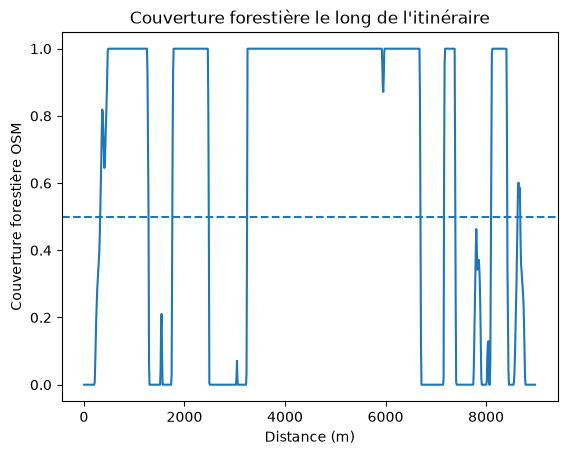

In [34]:
fig,ax = plt.subplots()
x = (forest_segments["start_m"] + forest_segments["end_m"]) / 2
ax.plot(x,forest_segments["forest_coverage"])
ax.axhline(FOREST_COVERAGE_THRESHOLD,linestyle="--")
ax.set_xlabel("Distance (m)")
ax.set_ylabel("Couverture forestière OSM")
ax.set_ylim(-0.05,1.05)
ax.set_title("Couverture forestière le long de l'itinéraire")
plt.show()

## 14. Fusionner les segments forestiers contigus

In [35]:
raw_groups = []
current = None

for _,row in forest_segments.iterrows():
    if not bool(row["is_forest"]):
        if current is not None:
            raw_groups.append(current)
            current = None
        continue

    c = float(row["forest_coverage"])

    if current is None:
        current = {
            "start_m":float(row["start_m"]),
            "end_m":float(row["end_m"]),
            "coverages":[c],
        }
    elif abs(float(row["start_m"]) - current["end_m"]) < 1e-6:
        current["end_m"] = float(row["end_m"])
        current["coverages"].append(c)
    else:
        raw_groups.append(current)
        current = {
            "start_m":float(row["start_m"]),
            "end_m":float(row["end_m"]),
            "coverages":[c],
        }

if current is not None:
    raw_groups.append(current)

final_forest_annotations = []

for g in raw_groups:
    vals = g["coverages"]

    final_forest_annotations.append({
        "feature":"foret",
        "family":"terrain",
        "start_m":g["start_m"],
        "end_m":g["end_m"],
        "resolution_m":10.0,
        "confidence":float(np.mean(vals)),
        "metrics":{
            "source":"OpenStreetMap",
            "retrieval_strategy":"bbox+is_in+pivot" + ("+expanded_bbox_rescue" if rescue_datasets else ""),
            "mean_forest_coverage":float(np.mean(vals)),
            "min_forest_coverage":float(np.min(vals)),
            "max_forest_coverage":float(np.max(vals)),
            "corridor_radius_m":CORRIDOR_RADIUS_M,
            "coverage_threshold":FOREST_COVERAGE_THRESHOLD,
            "n_base_segments":len(vals),
        },
    })

print("Portions forestières :", len(final_forest_annotations))
display(pd.DataFrame(final_forest_annotations))

Portions forestières : 6


,feature,family,start_m,end_m,resolution_m,confidence,metrics
0,foret,terrain,320.0,1290.0,10.0,0.949846,"{'source': 'OpenStreetMap', 'retrieval_strateg..."
1,foret,terrain,1760.0,2480.0,10.0,0.992790,"{'source': 'OpenStreetMap', 'retrieval_strateg..."
2,foret,terrain,3250.0,6690.0,10.0,0.998463,"{'source': 'OpenStreetMap', 'retrieval_strateg..."
3,foret,terrain,7160.0,7390.0,10.0,0.966941,"{'source': 'OpenStreetMap', 'retrieval_strateg..."
4,foret,terrain,8100.0,8420.0,10.0,0.979901,"{'source': 'OpenStreetMap', 'retrieval_strateg..."
5,foret,terrain,8630.0,8680.0,10.0,0.578604,"{'source': 'OpenStreetMap', 'retrieval_strateg..."


## 15. Export compatible avec le notebook 04

In [36]:
output_dir = Path("data/output")
output_dir.mkdir(parents=True,exist_ok=True)

forest_json_path = output_dir / "terrain_forest_annotations.json"
forest_csv_path = output_dir / "terrain_forest_annotations.csv"

with forest_json_path.open("w",encoding="utf-8") as f:
    json.dump(final_forest_annotations,f,ensure_ascii=False,indent=2)

pd.DataFrame([
    {
        **{k:v for k,v in a.items() if k != "metrics"},
        "metrics_json":json.dumps(a["metrics"],ensure_ascii=False),
    }
    for a in final_forest_annotations
]).to_csv(forest_csv_path,index=False)

print("Export :", forest_json_path)
print("Export :", forest_csv_path)

Export : data\output\terrain_forest_annotations.json
Export : data\output\terrain_forest_annotations.csv


## Diagnostic attendu

Sur votre trace test, l'ancienne version donnait environ 2,4 % de points GPX contenus dans les polygones récupérés.

Regardez maintenant :

```text
Couverture après bbox + is_in : XX %
COUVERTURE OSM FINALE : YY %
```

Si `XX` augmente fortement, le grand massif englobant a été récupéré par `is_in + pivot`.

Si `XX` reste faible mais `YY` augmente, c'est le fallback bbox élargi qui a récupéré une relation/multipolygone absente des `areas` Overpass.

Si les deux restent très faibles, la donnée OSM elle-même est probablement incomplète ou une relation très complexe est rejetée lors de la reconstruction.